# Benford's Law in Bulgarian Retail Prices

## Abstract

*Placeholder. We will write this at the end, when all results are in.*

## Data

The prices come from public store brochures. Stores in Bulgaria print these brochures every week to show their offers. The site shopi.bg collects them in one place, and our data was taken from there.

Each row is one product in one brochure. There are two columns:

- `price` - the price of the product
- `store` - the store that printed the brochure

Before the analysis we clean the data. We drop rows where the price is missing or is not a number. We also drop prices that are zero or negative, because a real price must be positive and zero has no first digit.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import benford

In [2]:
raw = pd.read_csv("data/prices.csv")
prices = benford.clean_prices(raw)

print("Rows before cleaning:", len(raw))
print("Rows after cleaning: ", len(prices))
print("Rows removed:        ", len(raw) - len(prices))

Rows before cleaning: 52164
Rows after cleaning:  52164
Rows removed:         0


No rows were removed. The export was already clean: every price is a positive number.

Here is how many prices we have from each store.

In [3]:
prices["store"].value_counts().rename("prices").to_frame()

,prices
store,
Kaufland,21874
Lidl,9868
Billa,7705
Lilly,3325
Dar,2201
T-Market,2098
BulMag,1766
Fantastico,1764
Metro,1199


Below is a histogram of all prices. Cheap products are much more common than expensive ones, so on a normal scale most bars would be squeezed on the left. We use a log scale on the x axis instead. On a log scale, the distance from 1 to 10 is the same as from 10 to 100, so all price ranges are easy to see.

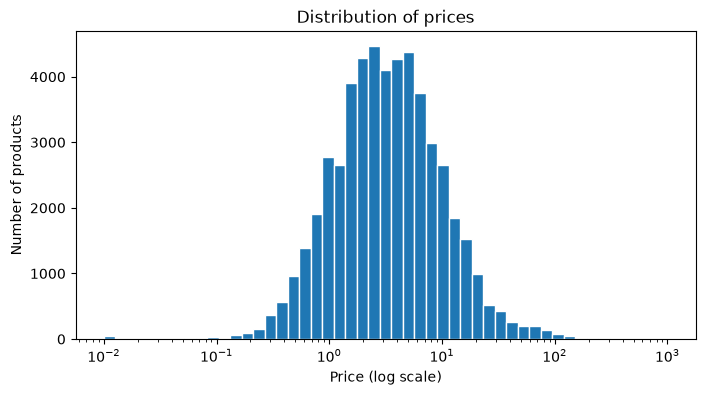

In [4]:
# Bins with equal width on the log scale
bins = np.logspace(np.log10(prices["price"].min()), np.log10(prices["price"].max()), 50)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(prices["price"], bins=bins, edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("Price (log scale)")
ax.set_ylabel("Number of products")
ax.set_title("Distribution of prices")
plt.show()